# 01. デフォルトのファクターリターン

レポートと同じ設定（デフォルト）でファクターリターンを計算します。

- **リターン**：現地通貨建てトータルリターン `ret`（固有リターン `sret` も選べます）
- **エクスポージャー**：前月末のスコアを Blom スコアに変換したもの
- **ファクターリターン**：日ごとに、リターンをエクスポージャーで 1 ファクターずつ単回帰した傾き

$$r_{it} = a_{kt} + f_{kt}\, z_{ik} + e_{it}$$

式の詳細は [docs/methodology.md](../docs/methodology.md) を参照してください。

In [1]:
import pandas as pd

from p_ken import charts, factors
from p_ken.report import NAM_COLORS
from p_ken.stats import annualized

START, END = "2026-01-01", "2026-09-30"  # 計算期間（年初来）
Q_START = "2026-07-01"  # 強調する四半期の初日
HIGHLIGHT = (Q_START, END)


def pct(x):
    """表示用：小数のリターンを +1.23% 形式の文字列に。"""
    return x.map("{:+.2%}".format)

## 1. 日次ファクターリターン（MSCI EM: AI / Revision / GEMQ3）

`nam_factor_returns` は、行 = 営業日、列 = ファクターの表を返します。値は小数（0.01 = 1%）です。

In [2]:
daily = factors.nam_factor_returns("gemq", START, END)  # ret_col="ret", method="regression"
print(daily.shape)
daily.tail().round(6)

(195, 3)


,AI,Revision,GEMQ3
2026-09-24,0.002209,-0.000436,0.001690
2026-09-25,-0.000386,0.000517,0.000001
2026-09-28,0.000862,-0.001715,0.000463
2026-09-29,-0.000227,-0.000632,-0.001080
2026-09-30,-0.000303,-0.001614,-0.001360


## 2. 四半期の合計（累和）

ファクターリターンは日次の値を足し合わせて（累和で）集計します。

In [3]:
pct(daily.loc[Q_START:].sum().to_frame("2026/07/01 - 09/30"))

,2026/07/01 - 09/30
AI,-1.65%
Revision,+0.84%
GEMQ3,-0.61%


## 3. 年率の集計

`annualized` は合計（`total`）、年率平均（`ann_ret`）、年率リスク（`ann_risk`）、
勝率（`hit`）、リスク・リターン比（`rr`）を返します。

In [4]:
annualized(daily).round(4)

,start,end,days,total,ann_ret,ann_risk,hit,rr
AI,2026-01-01,2026-09-30,195,0.0678,0.0876,0.0325,0.5949,2.6988
Revision,2026-01-01,2026-09-30,195,0.0701,0.0906,0.0437,0.5897,2.0745
GEMQ3,2026-01-01,2026-09-30,195,0.0928,0.1200,0.0387,0.6154,3.1019


## 4. 累和のグラフ

レポートと同じ作図関数です。右端の数字は強調期間（網掛け）の合計です。

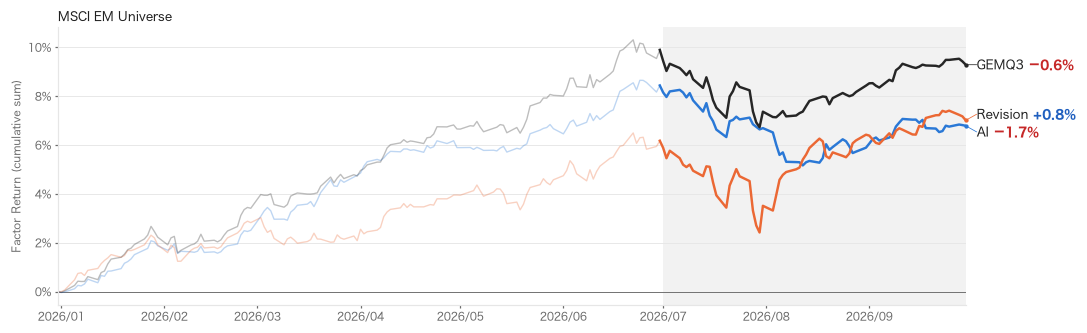

In [5]:
fig = charts.plot_cumulative(
    daily, START, HIGHLIGHT, "MSCI EM Universe", NAM_COLORS["gemq"], dpi=110
)

## 5. 固有リターン（`sret`）版

`ret_col="sret"` にすると、固有リターン（コモンファクターで説明されない部分）を被説明変数にします。

In [6]:
daily_sret = factors.nam_factor_returns("gemq", START, END, ret_col="sret")
pct(pd.DataFrame({"ret": daily.loc[Q_START:].sum(), "sret": daily_sret.loc[Q_START:].sum()}))

,ret,sret
AI,-1.65%,-0.31%
Revision,+0.84%,+0.11%
GEMQ3,-0.61%,-0.30%


## 6. Q5 超過リターン版

`method="q5"` にすると、回帰の傾きの代わりに「上位 20%（Q5）の平均リターン − 全銘柄の平均リターン」を使います。

In [7]:
daily_q5 = factors.nam_factor_returns("gemq", START, END, method="q5")
pct(
    pd.DataFrame(
        {"regression": daily.loc[Q_START:].sum(), "Q5 excess": daily_q5.loc[Q_START:].sum()}
    )
)

,regression,Q5 excess
AI,-1.65%,-2.98%
Revision,+0.84%,+2.79%
GEMQ3,-0.61%,+0.13%


## 7. RGA ユニバース

`"blf"` を指定すると RGA ユニバース（AI / TVL / RVL / 合成 ai70_bd30）で計算します。
RGA のスコアは日次ファイルで、各営業日にはその前日までで最新のファイルを使います。

,start,end,days,total,ann_ret,ann_risk,hit,rr
AI,2026-01-01,2026-09-30,195,0.0172,0.0223,0.0277,0.5026,0.8035
TVL,2026-01-01,2026-09-30,195,-0.0165,-0.0213,0.0238,0.4718,-0.8934
RVL,2026-01-01,2026-09-30,195,-0.0127,-0.0164,0.0228,0.4308,-0.7186
Composite (ai70_bd30),2026-01-01,2026-09-30,195,0.0121,0.0156,0.0251,0.5282,0.6209


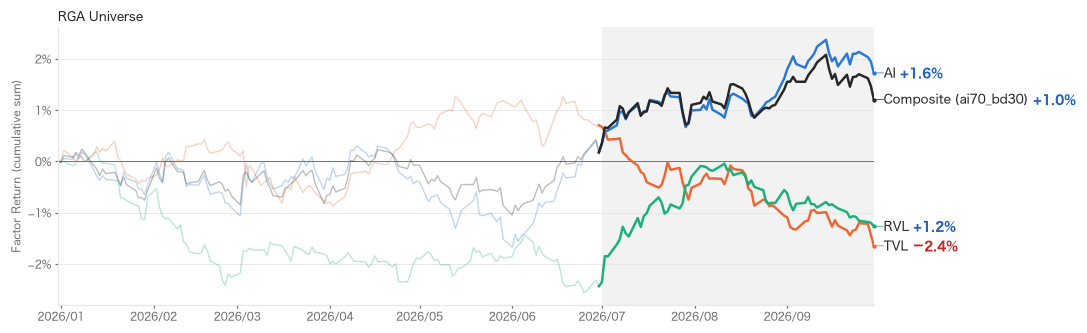

In [8]:
daily_blf = factors.nam_factor_returns("blf", START, END)
fig = charts.plot_cumulative(
    daily_blf, START, HIGHLIGHT, "RGA Universe", NAM_COLORS["blf"], dpi=110
)
annualized(daily_blf).round(4)